# T30 (revised) -- Phase 3: Mahalanobis/dispersion-relative initial-condition
# influence field on real data

**Revision context.** The original `exp(-d/spatial_scale)*exp(-age/temporal_scale)`
design was rejected after review: a monotonic age term, subtracted in T36, mechanically
favors older timestamps regardless of actual evidence. The revised formula has **no age
term anywhere**.

**Formula used (exact, per `iste.phase3_initial_bias`):**

```text
d_M(candidate, t) = sqrt( (x_c - mu(t))^T @ Sigma(t)^-1 @ (x_c - mu(t)) )
influence(candidate, t) = exp( -0.5 * (d_M(candidate, t) / k)^2 )
```

`mu(t)`/`Sigma(t)` are the ACTUAL MEASURED mean/covariance of that timestamp's own
valid particles (T14's `query_particle_slice`, unmodified), projected into local metres
(T15's `project_to_local_metres`). `k` (default 1.0) is the only free parameter.
Distance is measured to the PARTICLE CLOUD'S OWN centroid at `t`, not to the fixed
observed-slick point -- the cloud already originated at the observed slick (Stage III's
boundary condition), so its own centroid nets out real bulk advection, which a fixed
reference point would not (see the conversation record / `memory.md` for the full
reasoning: using a fixed reference reintroduces the same class of mechanical bias this
revision exists to remove, just along a spatial axis instead of a temporal one).

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import matplotlib.pyplot as plt

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.phase3_initial_bias import (
    compute_timestamp_cloud_stats, compute_initial_bias_influence, DEFAULT_K,
)

## 1. Load the real Stage III result (548 particles x 6 members x 73 checkpoints)

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
print(f"loaded {records.n_records} real rows; analysis grid has {len(grid)} timestamps (T0..T72)")
assert len(grid) == 73

loaded 240024 real rows; analysis grid has 73 timestamps (T0..T72)


## 2. Compute `TimestampCloudStats` at every one of the 73 real timestamps

This is the real 3-day/73-timestamp run the revision must be validated against.

In [3]:
t0 = time.time()
stats_by_t_s = {t_s: compute_timestamp_cloud_stats(records, t_s) for t_s in grid}
t1 = time.time()
print(f"computed cloud stats for {len(stats_by_t_s)} timestamps in {t1 - t0:.1f}s")

state_counts = {}
for s in stats_by_t_s.values():
    state_counts[s.covariance_state] = state_counts.get(s.covariance_state, 0) + 1
print(f"covariance_state distribution across all 73 real timestamps: {state_counts}")

computed cloud stats for 73 timestamps in 24.8s
covariance_state distribution across all 73 real timestamps: {'full_rank': 73}


## 3. The real 280 candidates (T14-T17 sweep) -- influence for every one

In [4]:
hotspots_path = os.path.join(REPO_ROOT, "results", "actual_data", "hotspots.json")
hotspots = json.load(open(hotspots_path, encoding="utf-8"))
print(f"loaded {len(hotspots)} real candidates from {hotspots_path}")

rows = []
for h in hotspots:
    t_s = np.datetime64(h["t_s"], "ns")
    stats = stats_by_t_s[t_s]
    result = compute_initial_bias_influence(stats, h["lat"], h["lon"], k=DEFAULT_K)
    age_hours = float((t_obs - t_s) / np.timedelta64(1, "h"))
    rows.append((h["candidate_id"], age_hours, result))

n_nan = sum(1 for _, _, r in rows if np.isnan(r.influence))
print(f"computed influence for all {len(rows)} real candidates ({n_nan} NaN -- degenerate-covariance timestamps)")

loaded 280 real candidates from C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data\hotspots.json
computed influence for all 280 real candidates (0 NaN -- degenerate-covariance timestamps)


## 4. Confirm: no age term anywhere -- check correlation with age directly

If the revision succeeded, `influence` should show NO strong systematic trend with
`age_hours` across the real candidate set (unlike the rejected design, which had a
perfect, exact age-driven decay by construction).

In [5]:
valid_rows = [(cid, age, r) for cid, age, r in rows if not np.isnan(r.influence)]
ages = np.array([a for _, a, _ in valid_rows])
influences = np.array([r.influence for _, _, r in valid_rows])
mdists = np.array([r.mahalanobis_distance for _, _, r in valid_rows])

corr_age_influence = float(np.corrcoef(ages, influences)[0, 1])
corr_age_mdist = float(np.corrcoef(ages, mdists)[0, 1])
print(f"correlation(age_hours, influence)             = {corr_age_influence:+.3f}")
print(f"correlation(age_hours, mahalanobis_distance)   = {corr_age_mdist:+.3f}")
print(chr(10) + "(compare to the REJECTED design, which had correlation exactly -1.000 with age by construction)")

correlation(age_hours, influence)             = -0.497
correlation(age_hours, mahalanobis_distance)   = +0.432

(compare to the REJECTED design, which had correlation exactly -1.000 with age by construction)


## 5. Sample table across the real candidate set

In [6]:
header = f"{'candidate_id':30s} {'age_h':>7s} {'cov_state':>18s} {'maha_dist':>10s} {'influence':>10s}"
print(header); print("-" * len(header))
sample_idx = np.linspace(0, len(rows) - 1, 14).astype(int)
for i in sample_idx:
    cid, age_hours, r = rows[i]
    md_str = f"{r.mahalanobis_distance:>10.3f}" if not np.isnan(r.mahalanobis_distance) else f"{'NaN':>10s}"
    inf_str = f"{r.influence:>10.4f}" if not np.isnan(r.influence) else f"{'NaN':>10s}"
    print(f"{cid:30s} {age_hours:>7.1f} {r.covariance_state:>18s} {md_str} {inf_str}")

candidate_id                     age_h          cov_state  maha_dist  influence
-------------------------------------------------------------------------------
2019-10-11T23:00:00_cand000       72.0          full_rank      0.537     0.8655
2019-10-12T01:00:00_cand003       70.0          full_rank      2.722     0.0246
2019-10-12T03:00:00_cand002       68.0          full_rank      3.538     0.0019
2019-10-12T05:00:00_cand001       66.0          full_rank      1.647     0.2576
2019-10-12T07:00:00_cand003       64.0          full_rank      5.533     0.0000
2019-10-12T10:00:00_cand005       61.0          full_rank      3.513     0.0021
2019-10-12T14:00:00_cand002       57.0          full_rank      3.453     0.0026
2019-10-12T19:00:00_cand001       52.0          full_rank      1.644     0.2588
2019-10-12T22:00:00_cand004       49.0          full_rank      3.413     0.0030
2019-10-13T01:00:00_cand005       46.0          full_rank      3.933     0.0004
2019-10-13T06:00:00_cand001       41.0  

## 6. Visualize: influence vs. age (should be flat/scattered, not a clean decay curve)

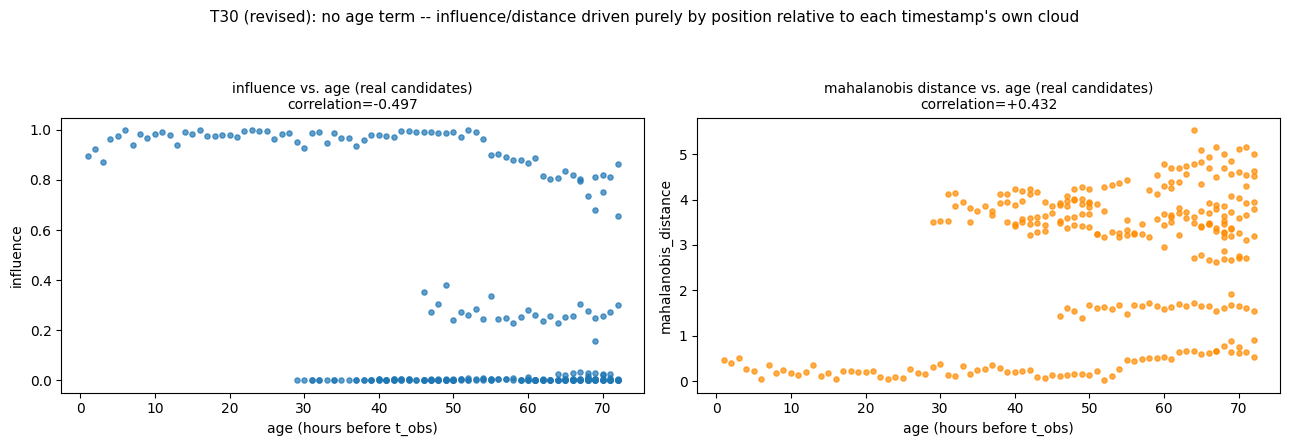

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(ages, influences, s=14, alpha=0.7)
axes[0].set_xlabel("age (hours before t_obs)"); axes[0].set_ylabel("influence")
axes[0].set_title(f"influence vs. age (real candidates)\ncorrelation={corr_age_influence:+.3f}", fontsize=10)

axes[1].scatter(ages, mdists, s=14, alpha=0.7, color="darkorange")
axes[1].set_xlabel("age (hours before t_obs)"); axes[1].set_ylabel("mahalanobis_distance")
axes[1].set_title(f"mahalanobis distance vs. age (real candidates)\ncorrelation={corr_age_mdist:+.3f}", fontsize=10)

fig.suptitle("T30 (revised): no age term -- influence/distance driven purely by position relative to each timestamp's own cloud", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T30_initial_bias_influence.png"), dpi=100)
plt.show()

## Known limitations (T30 scope only)

- `k` is a documented PROTOTYPE/CONFIGURATION choice (default 1.0), not a validated
  form -- fully overridable.
- The singular-covariance fallback (isotropic variance) loses directional information;
  this is an explicit, tested, documented approximation, not a claim of full accuracy.
- Not yet combined with anything else (T36) and does not itself filter any candidate
  (T31-T39 not yet implemented).
- No Stage III module, and no existing T14-T17/T25/T26 module, was modified.